# Week 2 Lab

DS 2023 | Communicating with Data

## Overview

In this week's lab, you will apply what you have learned about basic Pandas as well a data transformations.

You are encouraged to consult the notebooks in the course resource book for guidance, including [Panda Basics](https://ontoligent.github.io/DS2023/m02-04-pandasbasics/).

When finished, submit a URL to this notebook in your GitHub repo.

## Set Up

In [10]:
import pandas as pd

flights_data_url = "https://virginia.box.com/shared/static/hby5hxuvurkmatdxgy0p1ua7oftwl6i9.csv"
flights = pd.read_csv(flights_data_url, index_col=0)
flights.head()

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
1,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00
2,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01 05:00:00
3,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01 05:00:00
4,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01 05:00:00
5,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01 06:00:00


## Tasks

### Task 1 

1 pt

Create a dataframe called `flights_cho` that contains only observations with destinations `dest` as Charlottesville `CHO` and the columns 

In [8]:
flights_cho = flights.query("dest == 'CHO'")
flights_cho

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
137121,2013,3,1,2046.0,2045,1.0,2206.0,2220,-14.0,EV,5343,N197PQ,LGA,CHO,48.0,305,20,45,2013-03-01 20:00:00
138785,2013,3,3,2014.0,1940,34.0,2144.0,2121,23.0,EV,5325,N755EV,LGA,CHO,50.0,305,19,40,2013-03-03 19:00:00
139728,2013,3,4,1938.0,1940,-2.0,2133.0,2121,12.0,EV,5325,N611QX,LGA,CHO,54.0,305,19,40,2013-03-04 19:00:00
140798,2013,3,5,NaN,1940,NaN,NaN,2121,NaN,EV,5325,N611QX,LGA,CHO,NaN,305,19,40,2013-03-05 19:00:00
141647,2013,3,6,NaN,1940,NaN,NaN,2121,NaN,EV,5325,N611QX,LGA,CHO,NaN,305,19,40,2013-03-06 19:00:00
142549,2013,3,7,1946.0,1940,6.0,2116.0,2121,-5.0,EV,5325,N708EV,LGA,CHO,50.0,305,19,40,2013-03-07 19:00:00
143574,2013,3,8,2355.0,1940,255.0,109.0,2121,228.0,EV,5325,N611QX,LGA,CHO,42.0,305,19,40,2013-03-08 19:00:00
145345,2013,3,10,2031.0,1940,51.0,2151.0,2121,30.0,EV,5325,N371CA,LGA,CHO,51.0,305,19,40,2013-03-10 19:00:00
146283,2013,3,11,1937.0,1940,-3.0,2118.0,2121,-3.0,EV,5325,N760EV,LGA,CHO,67.0,305,19,40,2013-03-11 19:00:00
147271,2013,3,12,2145.0,1940,125.0,2306.0,2121,105.0,EV,5325,N371CA,LGA,CHO,56.0,305,19,40,2013-03-12 19:00:00


### Task 2

3 pts

Using the dataframe you created, answer the following questions using dataframe methods, i.e. not by visually inspecting the dataframe:

**How many flights are there from any New York airport to Charlottesville?**

In [13]:
flights_ny_cho = flights_cho.query("origin=='LGA'")
len(flights_ny_cho)

52

**How many carriers fly to Charlottesville?**

In [14]:
len(flights_cho['carrier'])

52

**What is mean flight time for trips from New York to Charlottesville?**

In [17]:
flights_ny_cho['air_time'].mean()

np.float64(50.95652173913044)

### Task 3

3 pts

Using method chaining on the original table `flights`, create a wide table called `flights_atl` with month on axis 1 and day on axis 2 showing the number of flights to Atlanta `ATL`. Make sure the days are in order (from 1 to 31).

In [22]:
flights_atl = flights.query("dest=='ATL'")

flights_atl.value_counts(['month','day']).head(1)

month  day
4      15     55
Name: count, dtype: int64

In [26]:
flights_atl.nunique()

year                 1
month               12
day                 31
dep_time          1070
sched_dep_time     232
dep_delay          339
arr_time          1095
sched_arr_time     587
arr_delay          371
carrier              7
flight             300
tailnum           1179
origin               3
dest                 1
air_time            86
distance             3
hour                17
minute              48
time_hour         5603
dtype: int64

In [37]:

flights_atl = (flights.query("dest=='ATL'")
               .groupby(['year','day','month'])
               .size()
               .unstack()
               .sort_index()
                       )

flights_atl

month       1     2     3     4     5     6     7     8     9     10    11  \
year day                                                                     
2013 1    40.0  49.0  48.0  51.0  51.0  38.0  47.0  52.0  39.0  49.0  50.0   
     2    51.0  35.0  37.0  49.0  50.0  47.0  48.0  52.0  48.0  50.0  34.0   
     3    49.0  40.0  46.0  50.0  50.0  49.0  52.0  38.0  49.0  50.0  46.0   
     4    48.0  49.0  50.0  49.0  38.0  49.0  35.0  48.0  48.0  50.0  49.0   
     5    35.0  47.0  49.0  50.0  48.0  51.0  42.0  53.0  48.0  34.0  50.0   
     6    41.0  47.0  50.0  36.0  51.0  50.0  38.0  52.0  48.0  44.0  49.0   
     7    49.0  48.0  49.0  45.0  51.0  50.0  48.0  52.0  33.0  51.0  49.0   
     8    47.0  48.0  50.0  51.0  51.0  38.0  53.0  52.0  43.0  49.0  51.0   
     9    47.0  35.0  37.0  53.0  50.0  46.0  52.0  52.0  49.0  50.0  34.0   
     10   48.0  41.0  45.0  53.0  50.0  52.0  52.0  39.0  49.0  50.0  47.0   
     11   48.0  49.0  50.0  53.0  38.0  51.0  52.0  48.0  46.0  50.0  49.0   
     12   35.0  47.0  49.0  53.0  48.0  51.0  52.0  53.0  50.0  33.0  51.0   
     13   42.0  47.0  50.0  37.0  51.0  51.0  39.0  51.0  49.0  44.0  50.0   
     14   49.0  48.0  49.0  48.0  51.0  51.0  48.0  51.0  33.0  50.0  49.0   
     15   47.0  49.0  50.0  55.0  51.0  37.0  53.0  51.0  43.0  49.0  51.0   
     16   47.0  36.0  36.0  53.0  50.0  47.0  52.0  51.0  49.0  50.0  34.0   
     17   48.0  36.0  45.0  53.0  50.0  52.0  52.0  39.0  48.0  50.0  48.0   
     18   48.0  49.0  50.0  53.0  38.0  51.0  52.0  46.0  48.0  50.0  49.0   
     19   34.0  48.0  49.0  53.0  48.0  52.0  52.0  52.0  49.0  34.0  51.0   
     20   38.0  48.0  50.0  38.0  51.0  51.0  39.0  52.0  49.0  44.0  50.0   
     21   48.0  49.0  49.0  48.0  51.0  51.0  48.0  51.0  33.0  50.0  49.0   
     22   47.0  48.0  50.0  54.0  51.0  38.0  53.0  51.0  43.0  49.0  51.0   
     23   47.0  36.0  36.0  53.0  50.0  47.0  52.0  51.0  49.0  50.0  36.0   
     24   48.0  43.0  45.0  53.0  50.0  52.0  52.0  39.0  48.0  50.0  46.0   
     25   48.0  50.0  50.0  53.0  36.0  51.0  52.0  46.0  48.0  49.0  47.0   
     26   35.0  48.0  49.0  53.0  41.0  51.0  52.0  52.0  49.0  34.0  50.0   
     27   41.0  48.0  50.0  38.0  51.0  51.0  39.0  49.0  49.0  44.0  51.0   
     28   49.0  49.0  49.0  48.0  52.0  51.0  48.0  50.0  35.0  49.0  33.0   
     29   47.0   NaN  50.0  54.0  51.0  38.0  53.0  50.0  43.0  50.0  34.0   
     30   47.0   NaN  36.0  53.0  50.0  44.0  52.0  50.0  49.0  49.0  46.0   
     31   48.0   NaN  45.0   NaN  50.0   NaN  52.0  34.0   NaN  43.0   NaN   

month       12  
year day        
2013 1    49.0  
     2    49.0  
     3    52.0  
     4    51.0  
     5    50.0  
     6    52.0  
     7    35.0  
     8    47.0  
     9    50.0  
     10   51.0  
     11   51.0  
     12   50.0  
     13   52.0  
     14   35.0  
     15   47.0  
     16   50.0  
     17   51.0  
     18   51.0  
     19   51.0  
     20   53.0  
     21   42.0  
     22   45.0  
     23   49.0  
     24   38.0  
     25   37.0  
     26   48.0  
     27   53.0  
     28   42.0  
     29   44.0  
     30   49.0  
     31   39.0

### Task 4

2 pts

Using the wide table you just created, compute the sum of flights for each month. 

In [44]:
flights_atl.agg('sum')

month
1     1396.0
2     1267.0
3     1448.0
4     1490.0
5     1499.0
6     1438.0
7     1511.0
8     1507.0
9     1364.0
10    1448.0
11    1384.0
12    1463.0
dtype: float64

Chain the method `.idxmax()` on the preceding series to compute the month with the most flights.

In [45]:
flights_atl.agg('sum').idxmax()

np.int64(7)

### Task 5

1 pt

Chain the method `.plot()` to the previous saved series.

<Axes: xlabel='month'>

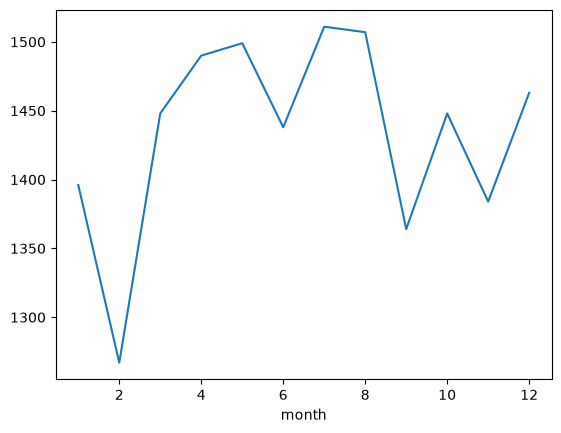

In [47]:
flights_atl.agg('sum').plot()